In [38]:
import numpy as np  #numpy 是python专门处理数学运算的包
import scipy as sp  #scipy 是python专门处理科学运算的包，包含很多算法
import pandas as pd #pandas 是python用来进行数据分析和研究的包，非常适合社会科学工作者

import matplotlib #python 专门用于画图的包
from matplotlib import pyplot as plt
import matplotlib.font_manager as font_manager
import seaborn as sns  #a high-level Python data visualization library based on matplotlib. 
from matplotlib.pyplot import cm
%matplotlib inline


import warnings
warnings.filterwarnings("ignore")
import platform
if platform.system() == "Darwin":
    # 简易设置以让matplotlib能显示中文
    plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
elif platform.system() == "Windows":
    plt.rcParams['font.sans-serif'] = ['SimHei']  # 简易设置以让matplotlib能显示中文
    plt.rcParams['axes.unicode_minus']=False #用来正常显示负号
else:
    pass


from collections import Counter, defaultdict # 字典函数，下面会用到

In [39]:
#读取csv数据
df = pd.read_csv('C:\\Users\\Administrator\\Downloads\\archive (2)\\dating_app_behavior_dataset_extended1.csv')

In [40]:
df.shape #列的形状

(50000, 25)

In [41]:
df.dtypes #列的数据类型

gender                   object
sexual_orientation       object
location_type            object
income_bracket           object
education_level          object
interest_tags            object
app_usage_time_min        int64
app_usage_time_label     object
swipe_right_ratio       float64
swipe_right_label        object
likes_received            int64
mutual_matches            int64
profile_pics_count        int64
bio_length                int64
message_sent_count        int64
emoji_usage_rate        float64
last_active_hour          int64
swipe_time_of_day        object
match_outcome            object
age                       int64
height_cm                 int64
weight_kg               float64
zodiac_sign              object
body_type                object
relationship_intent      object
dtype: object

In [42]:
df.info() #列的总和

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gender                50000 non-null  object 
 1   sexual_orientation    50000 non-null  object 
 2   location_type         50000 non-null  object 
 3   income_bracket        50000 non-null  object 
 4   education_level       50000 non-null  object 
 5   interest_tags         50000 non-null  object 
 6   app_usage_time_min    50000 non-null  int64  
 7   app_usage_time_label  50000 non-null  object 
 8   swipe_right_ratio     50000 non-null  float64
 9   swipe_right_label     50000 non-null  object 
 10  likes_received        50000 non-null  int64  
 11  mutual_matches        50000 non-null  int64  
 12  profile_pics_count    50000 non-null  int64  
 13  bio_length            50000 non-null  int64  
 14  message_sent_count    50000 non-null  int64  
 15  emoji_usage_rate   

In [43]:
df.head(5) 

,gender,sexual_orientation,location_type,income_bracket,education_level,interest_tags,app_usage_time_min,app_usage_time_label,swipe_right_ratio,swipe_right_label,...,emoji_usage_rate,last_active_hour,swipe_time_of_day,match_outcome,age,height_cm,weight_kg,zodiac_sign,body_type,relationship_intent
0,Prefer Not to Say,Gay,Urban,High,Bachelor’s,"Fitness, Politics, Traveling",52,Moderate,0.60,Optimistic,...,0.36,13,Early Morning,Mutual Match,56,149,40.6,Taurus,Curvy,Friends Only
1,Male,Bisexual,Suburban,Upper-Middle,No Formal Education,"Languages, Fashion, Parenting",279,Extreme User,0.56,Optimistic,...,0.42,0,Morning,Chat Ignored,40,155,69.7,Leo,Plus Size,Hookups
2,Non-binary,Pansexual,Suburban,Low,Master’s,"Movies, Reading, DIY",49,Moderate,0.41,Optimistic,...,0.41,1,After Midnight,Date Happened,30,185,96.9,Sagittarius,Curvy,Serious Relationship
3,Genderfluid,Gay,Metro,Very Low,Postdoc,"Coding, Podcasts, History",185,Extreme User,0.32,Balanced,...,0.07,21,Morning,No Action,57,154,49.3,Taurus,Slim,Exploring
4,Male,Bisexual,Urban,Middle,Bachelor’s,"Clubbing, Podcasts, Cars",83,High,0.32,Balanced,...,0.11,22,After Midnight,One-sided Like,24,149,40.0,Libra,Slim,Casual Dating


In [44]:
df.isnull().sum() #缺失值

gender                  0
sexual_orientation      0
location_type           0
income_bracket          0
education_level         0
interest_tags           0
app_usage_time_min      0
app_usage_time_label    0
swipe_right_ratio       0
swipe_right_label       0
likes_received          0
mutual_matches          0
profile_pics_count      0
bio_length              0
message_sent_count      0
emoji_usage_rate        0
last_active_hour        0
swipe_time_of_day       0
match_outcome           0
age                     0
height_cm               0
weight_kg               0
zodiac_sign             0
body_type               0
relationship_intent     0
dtype: int64

In [45]:
df.dropna()

,gender,sexual_orientation,location_type,income_bracket,education_level,interest_tags,app_usage_time_min,app_usage_time_label,swipe_right_ratio,swipe_right_label,...,emoji_usage_rate,last_active_hour,swipe_time_of_day,match_outcome,age,height_cm,weight_kg,zodiac_sign,body_type,relationship_intent
0,Prefer Not to Say,Gay,Urban,High,Bachelor’s,"Fitness, Politics, Traveling",52,Moderate,0.60,Optimistic,...,0.36,13,Early Morning,Mutual Match,56,149,40.6,Taurus,Curvy,Friends Only
1,Male,Bisexual,Suburban,Upper-Middle,No Formal Education,"Languages, Fashion, Parenting",279,Extreme User,0.56,Optimistic,...,0.42,0,Morning,Chat Ignored,40,155,69.7,Leo,Plus Size,Hookups
2,Non-binary,Pansexual,Suburban,Low,Master’s,"Movies, Reading, DIY",49,Moderate,0.41,Optimistic,...,0.41,1,After Midnight,Date Happened,30,185,96.9,Sagittarius,Curvy,Serious Relationship
3,Genderfluid,Gay,Metro,Very Low,Postdoc,"Coding, Podcasts, History",185,Extreme User,0.32,Balanced,...,0.07,21,Morning,No Action,57,154,49.3,Taurus,Slim,Exploring
4,Male,Bisexual,Urban,Middle,Bachelor’s,"Clubbing, Podcasts, Cars",83,High,0.32,Balanced,...,0.11,22,After Midnight,One-sided Like,24,149,40.0,Libra,Slim,Casual Dating
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,Transgender,Gay,Metro,Very High,Postdoc,"Gaming, Writing, Painting",130,Addicted,0.69,Optimistic,...,0.19,15,Afternoon,Ghosted,45,195,102.7,Pisces,Plus Size,Casual Dating
49996,Female,Lesbian,Small Town,Low,Diploma,"Traveling, Fitness, Stand-up Comedy",277,Extreme User,0.43,Optimistic,...,0.23,2,Evening,Ghosted,26,185,79.7,Leo,Athletic,Friends Only
49997,Male,Bisexual,Remote Area,High,High School,"Gaming, Motorcycling, Art",73,High,0.50,Optimistic,...,0.36,5,After Midnight,Blocked,45,176,69.1,Pisces,Athletic,Serious Relationship
49998,Transgender,Queer,Urban,Low,MBA,"Skating, Astrology, Hiking",100,High,0.34,Balanced,...,0.36,16,Evening,One-sided Like,29,171,83.6,Libra,Athletic,Friends Only


In [46]:
df.dropna(subset=['gender'], inplace=True)  ## 在列删除缺失值，直接作用于原数据

In [47]:
df.dropna(subset=['sexual_orientation'], inplace=True)  ## 在列删除缺失值，直接作用于原数据

In [48]:
df.dropna(subset=['income_bracket'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [49]:
df.dropna(subset=['location_type'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [50]:
df.dropna(subset=['education_level'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [51]:
df.dropna(subset=['interest_tags'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [52]:
df.dropna(subset=['app_usage_time_min'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [53]:
df.dropna(subset=['app_usage_time_label'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [54]:
df.dropna(subset=['swipe_right_ratio'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据“

In [55]:
df.dropna(subset=['swipe_right_label'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [56]:
df.dropna(subset=['emoji_usage_rate'], inplace=True)  ## 在'text'列删除缺失值，直接作用于原数据

In [57]:
df.shape

(50000, 25)

In [58]:
df['gender'].unique()  

array(['Prefer Not to Say', 'Male', 'Non-binary', 'Genderfluid', 'Female',
       'Transgender'], dtype=object)

In [64]:
# 定义性别映射字典
gender_mapping = {
    'Male': '男性',
    'Female': '女性',
    'Non-binary': '非二元性别',
    'Genderfluid': '性别流动',
    'Transgender': '跨性别者',
    'Prefer Not to Say': '不愿透露'
}

# 应用替换（假设您的DataFrame名为 df）
df['gender'] = df['gender'].replace(gender_mapping)

# 验证结果
print(df['gender'].value_counts())

gender
女性       8384
非二元性别    8366
跨性别者     8353
不愿透露     8335
性别流动     8307
男性       8255
Name: count, dtype: int64


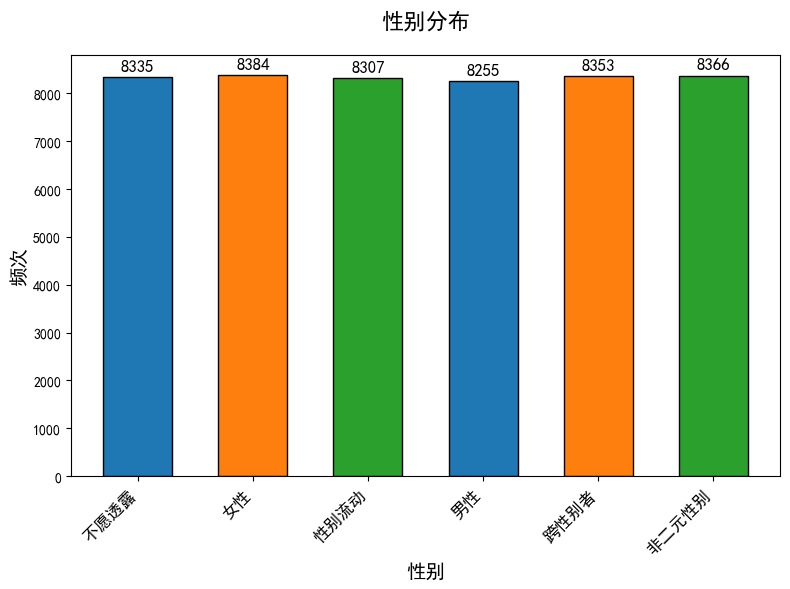

In [65]:
# 设置图表尺寸和样式
plt.figure(figsize=(8, 6), dpi=100)  # 增大画布尺寸
ax = plt.gca()

# 获取数据
x = df['gender']
labels, counts = np.unique(x, return_counts=True)

# 绘制条形图（调整条宽和间距）
bars = ax.bar(labels, counts, 
             width=0.6,      # 缩小条宽
             color=['#1f77b4', '#ff7f0e', '#2ca02c'],  # 自定义颜色
             edgecolor='black')

# 设置标签和标题（增大字体）
ax.set_title("性别分布", fontsize=16, pad=20)  # pad增加标题间距
ax.set_ylabel("频次", fontsize=14)
ax.set_xlabel("性别", fontsize=14)

# 优化刻度标签
ax.set_xticks(np.arange(len(labels)))  # 确保刻度居中
ax.set_xticklabels(labels, 
                  rotation=45,         # 旋转45度避免重叠
                  ha='right',          # 对齐方式
                  fontsize=12)

# 添加数据标签
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=12)

# 自动调整布局
plt.tight_layout()  # 解决标签截断问题

# 显示图表
plt.show()

In [61]:
df['sexual_orientation'].unique()  

array(['Gay', 'Bisexual', 'Pansexual', 'Lesbian', 'Asexual', 'Queer',
       'Straight', 'Demisexual'], dtype=object)

In [66]:
# 定义性取向映射字典
orientation_mapping = {
    'Gay': '男同性恋',
    'Lesbian': '女同性恋',
    'Bisexual': '双性恋',
    'Pansexual': '泛性恋',
    'Asexual': '无性恋',
    'Queer': '酷儿',
    'Straight': '异性恋',
    'Demisexual': '半性恋'
}

# 应用替换（假设您的DataFrame名为 df）
df['sexual_orientation'] = df['sexual_orientation'].replace(orientation_mapping)

# 验证结果
print(df['sexual_orientation'].value_counts())

sexual_orientation
异性恋     6326
女同性恋    6315
半性恋     6301
酷儿      6288
无性恋     6254
泛性恋     6237
双性恋     6158
男同性恋    6121
Name: count, dtype: int64


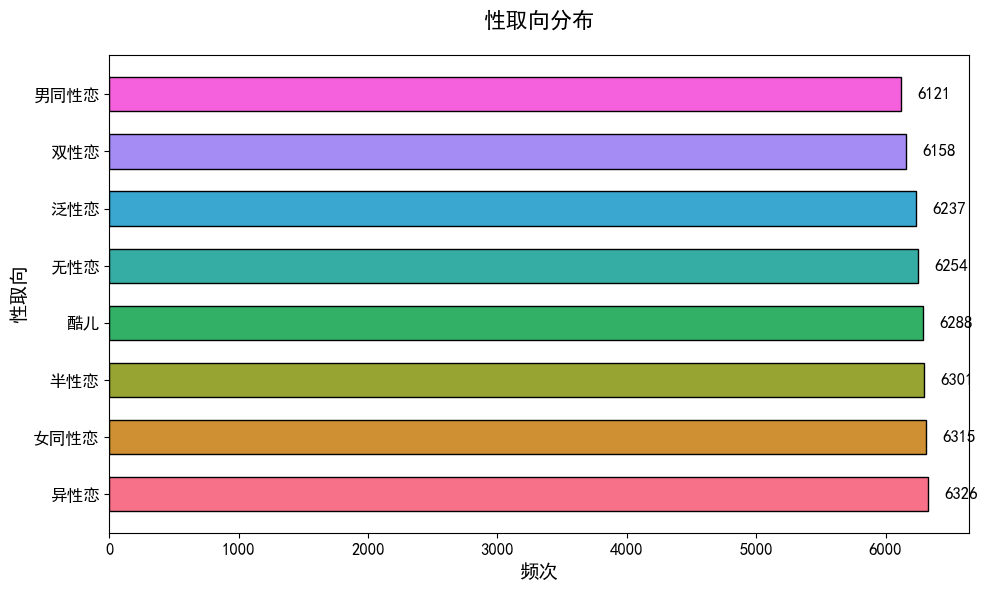

In [68]:
# 设置图表尺寸和样式
plt.figure(figsize=(10, 6), dpi=100)  # 横向扩展以适应长标签
ax = plt.gca()

# 获取数据（性取向列）
x = df['sexual_orientation']
labels, counts = np.unique(x, return_counts=True)

# 按频次排序（可选，使条形图按高低排序）
sort_idx = np.argsort(counts)[::-1]
labels = labels[sort_idx]
counts = counts[sort_idx]

# 绘制横向条形图（解决长标签遮挡问题）
bars = ax.barh(labels, counts, 
              height=0.6,          # 条高
              color=sns.color_palette("husl", len(labels)),  # 多色区分
              edgecolor='black')

# 设置标签和标题
ax.set_title("性取向分布", fontsize=16, pad=20)
ax.set_xlabel("频次", fontsize=14)
ax.set_ylabel("性取向", fontsize=14)

# 优化刻度标签
ax.tick_params(axis='y', labelsize=12)  # Y轴标签（性取向）字体大小
ax.tick_params(axis='x', labelsize=12)  # X轴标签（频次）字体大小

# 添加数据标签（右侧显示）
for bar in bars:
    width = bar.get_width()
    ax.text(width + max(counts)*0.02,  # 标签位置向右偏移2%最大值
            bar.get_y() + bar.get_height()/2,
            f'{width}',
            va='center', ha='left',     # 左对齐
            fontsize=12)

# 自动调整布局
plt.tight_layout()

# 显示图表
plt.show()

In [71]:
df['income_bracket'].unique()  

array(['高收入', '中高收入', '低收入', '极低收入', '中等收入', '中低收入', '极高收入'], dtype=object)

In [73]:
income_mapping = {
    'Very Low': '极低收入',
    'Low': '低收入',
    'Lower-Middle': '中低收入',
    'Middle': '中等收入',
    'Upper-Middle': '中高收入',
    'High': '高收入',
    'Very High': '极高收入'
}

# 应用中文标签（确保列名正确）
df['income_bracket'] = df['income_bracket'].replace(income_mapping)

# 验证结果
print(df['income_bracket'].value_counts())

income_bracket
高收入     7309
极高收入    7178
低收入     7132
中等收入    7126
中低收入    7118
中高收入    7076
极低收入    7061
Name: count, dtype: int64


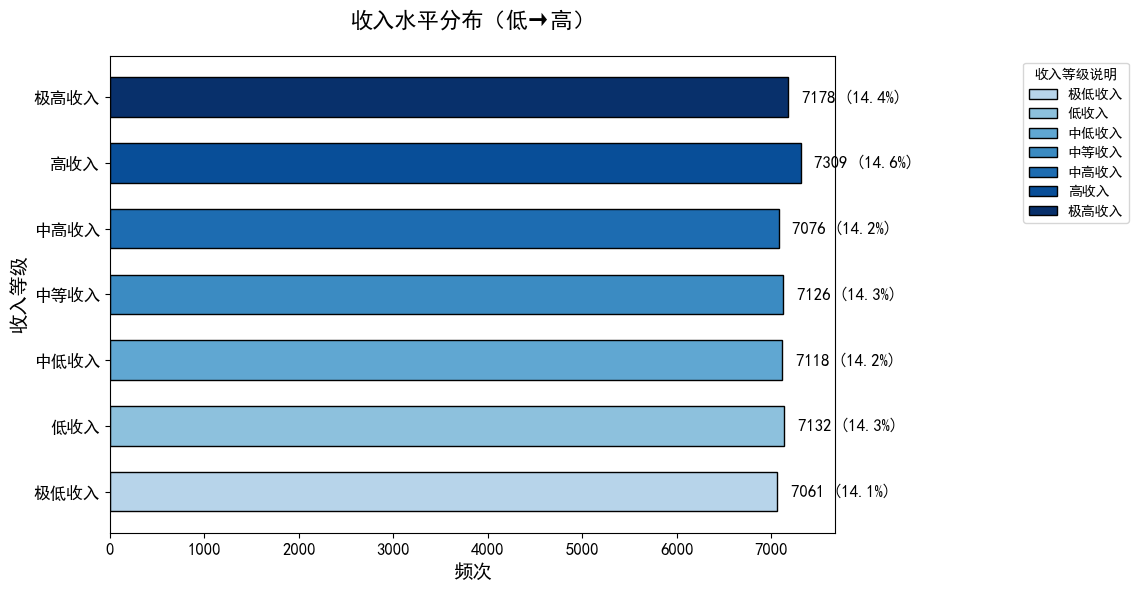

In [74]:
# 设置图表尺寸和样式
plt.figure(figsize=(12, 6), dpi=100)
ax = plt.gca()

# 定义收入等级顺序（确保从低到高）
income_order = ['极低收入', '低收入', '中低收入', '中等收入', '中高收入', '高收入', '极高收入']

# 按定义顺序统计数据
counts = df['income_bracket'].value_counts().loc[income_order].values

# 生成渐变色（低→高，使用蓝色渐变）
colors = plt.cm.Blues(np.linspace(0.3, 1, len(income_order)))

# 绘制横向条形图
bars = ax.barh(income_order, counts, 
              height=0.6,          # 条高
              color=colors,        # 渐变色方案
              edgecolor='black')

# 设置标签和标题
ax.set_title("收入水平分布（低→高）", fontsize=16, pad=20)
ax.set_xlabel("频次", fontsize=14)
ax.set_ylabel("收入等级", fontsize=14)

# 优化刻度标签
ax.tick_params(axis='y', labelsize=12)  # Y轴标签（收入等级）
ax.tick_params(axis='x', labelsize=12)  # X轴标签（频次）

# 添加数据标签（右侧显示频次和百分比）
total = len(df)
for bar in bars:
    width = bar.get_width()
    percent = width / total * 100
    ax.text(width + max(counts)*0.02,  # 标签位置向右偏移2%最大值
            bar.get_y() + bar.get_height()/2,
            f'{width} ({percent:.1f}%)',  # 格式：频次 (百分比%)
            va='center', ha='left', 
            fontsize=12)

# 添加颜色渐变图例（右侧）
from matplotlib.patches import Patch
gradient_steps = [Patch(facecolor=colors[i], 
                       edgecolor='black', 
                       label=f'{income_order[i]}') 
                 for i in range(len(income_order))]
ax.legend(handles=gradient_steps, 
         title="收入等级说明",
         bbox_to_anchor=(1.25, 1), 
         loc='upper left',
         fontsize=10)

# 自动调整布局
plt.tight_layout()

# 显示图表
plt.show()

In [27]:
df['location_type'].unique()  

array(['Urban', 'Suburban', 'Metro', 'Small Town', 'Remote Area', 'Rural'],
      dtype=object)

In [28]:
# 定义合并规则
def merge_location(loc):
    if loc in ['Rural', 'Remote Area']:
        return '农村及偏远地区'
    elif loc in ['Small Town', 'Suburban']:
        return '城镇带'
    elif loc in ['Urban', 'Metro']:
        return '都市区'
    else:
        return '其他'

# 应用合并
df['location_merged'] = df['location_type'].apply(merge_location)

# 验证分布
print(df['location_merged'].value_counts())

location_merged
农村及偏远地区    16850
城镇带        16639
都市区        16511
Name: count, dtype: int64


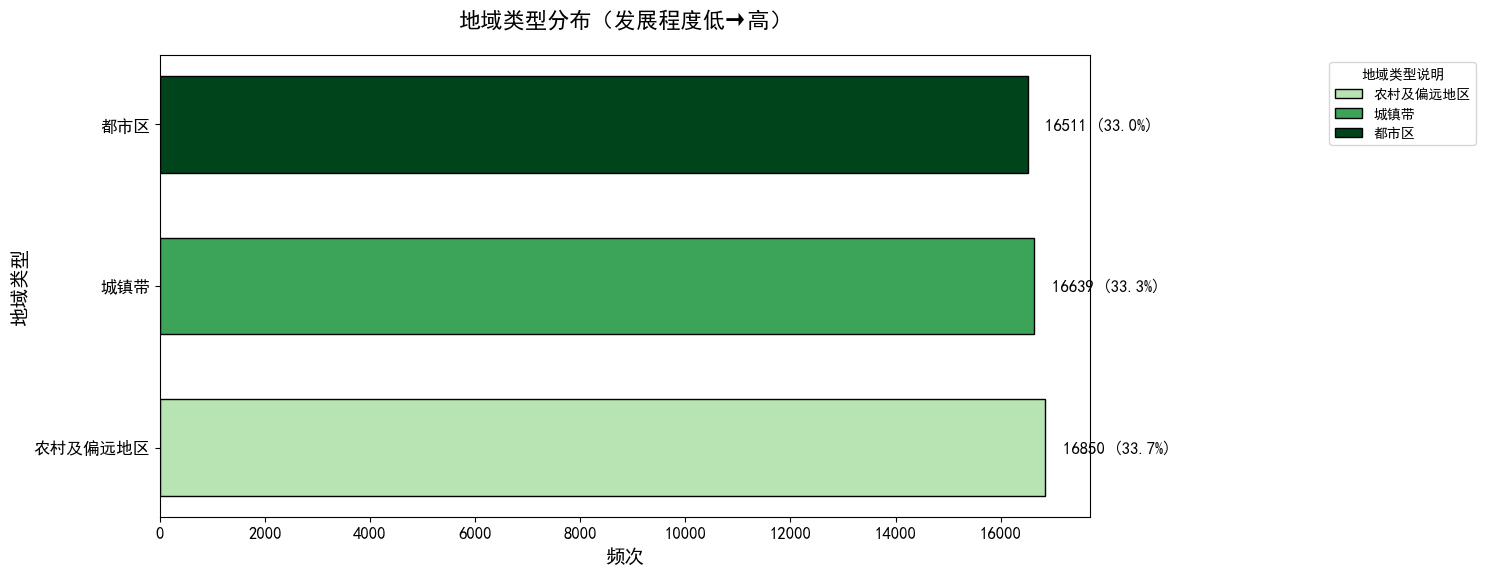

In [79]:
# 设置图表尺寸和样式
plt.figure(figsize=(12, 6), dpi=100)
ax = plt.gca()

# 定义地域类型顺序（按发展程度从低到高）
location_order = ['农村及偏远地区', '城镇带', '都市区']

# 按定义顺序统计数据
counts = df['location_merged'].value_counts().loc[location_order].values

# 生成渐变色（低→高，使用绿色渐变）
colors = plt.cm.Greens(np.linspace(0.3, 1, len(location_order)))

# 绘制横向条形图
bars = ax.barh(location_order, counts, 
              height=0.6,          # 条高
              color=colors,        # 渐变色方案
              edgecolor='black')

# 设置标签和标题
ax.set_title("地域类型分布（发展程度低→高）", fontsize=16, pad=20)
ax.set_xlabel("频次", fontsize=14)
ax.set_ylabel("地域类型", fontsize=14)

# 优化刻度标签
ax.tick_params(axis='y', labelsize=12)  # Y轴标签（地域类型）
ax.tick_params(axis='x', labelsize=12)  # X轴标签（频次）

# 添加数据标签（右侧显示频次和百分比）
total = len(df)
for bar in bars:
    width = bar.get_width()
    percent = width / total * 100
    ax.text(width + max(counts)*0.02,  # 标签位置向右偏移2%最大值
            bar.get_y() + bar.get_height()/2,
            f'{width} ({percent:.1f}%)',  # 格式：频次 (百分比%)
            va='center', ha='left', 
            fontsize=12)

# 添加颜色渐变图例（右侧）
from matplotlib.patches import Patch
gradient_steps = [Patch(facecolor=colors[i], 
                       edgecolor='black', 
                       label=f'{location_order[i]}') 
                 for i in range(len(location_order))]
ax.legend(handles=gradient_steps, 
         title="地域类型说明",
         bbox_to_anchor=(1.25, 1), 
         loc='upper left',
         fontsize=10)



# 显示图表
plt.show()

In [29]:
df['education_level'].unique() 

array(['Bachelor’s', 'No Formal Education', 'Master’s', 'Postdoc',
       'Associate’s', 'High School', 'Diploma', 'PhD', 'MBA'],
      dtype=object)

In [80]:
education_mapping = {
    'Bachelor’s': '学士',
    'Master’s': '硕士',
    'PhD': '博士',
    'MBA': '工商管理硕士',
    'Postdoc': '博士后',
    'Associate’s': '副学士',
    'High School': '高中',
    'Diploma': '文凭课程',
    'No Formal Education': '无正规教育'
}

# 应用替换（假设列名为 'education_level'）
df['education_level'] = df['education_level'].replace(education_mapping)

# 验证结果
print(df['education_level'].value_counts())

education_level
学士        5646
工商管理硕士    5637
高中        5632
博士        5594
无正规教育     5569
硕士        5503
副学士       5499
博士后       5473
文凭课程      5447
Name: count, dtype: int64


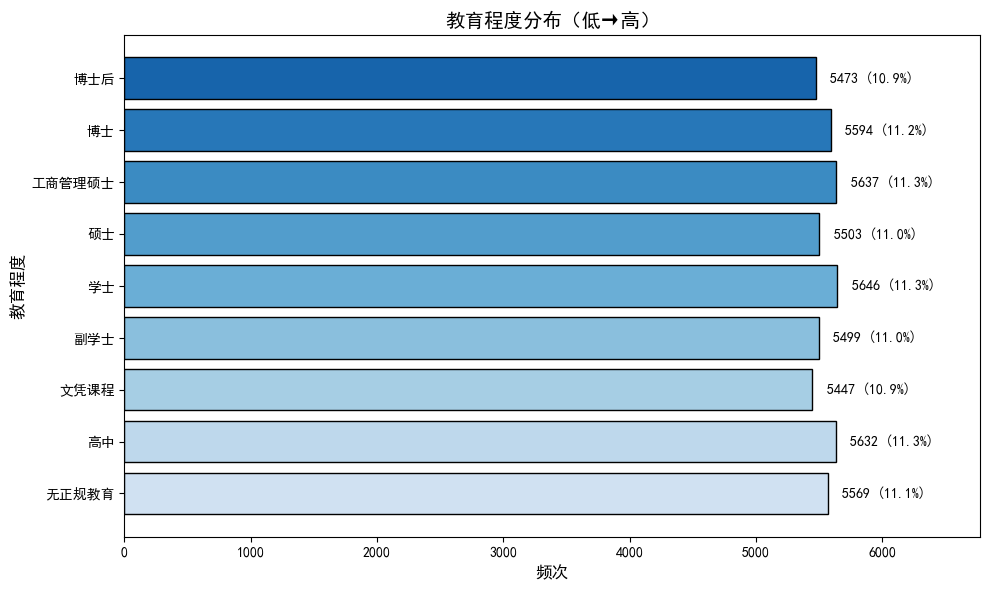

In [83]:
import matplotlib.pyplot as plt
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 定义教育程度顺序
edu_order = ['无正规教育', '高中', '文凭课程', '副学士', '学士', '硕士', '工商管理硕士', '博士', '博士后']

# 准备数据
edu_counts = df['education_level'].value_counts().reindex(edu_order, fill_value=0)
total = len(df)
percentages = (edu_counts / total * 100).round(1)

# 生成渐变色（低→高：浅蓝→深蓝）
colors = plt.cm.Blues(np.linspace(0.2, 0.8, len(edu_order)))

# 创建图表
fig, ax = plt.subplots(figsize=(10,6))

# 绘制横向条形图
bars = ax.barh(
    edu_order, 
    edu_counts,
    color=colors,
    edgecolor='black'
)

# 添加双标签（频次 + 百分比）
for i, (count, percent) in enumerate(zip(edu_counts, percentages)):
    ax.text(
        count + max(edu_counts)*0.02,  # 动态调整标签位置
        i,
        f'{count} ({percent}%)',
        va='center',
        fontsize=10
    )

# 设置图表元素
ax.set_title("教育程度分布（低→高）", fontsize=14)
ax.set_xlabel("频次", fontsize=12)
ax.set_ylabel("教育程度", fontsize=12)
ax.set_xlim(0, max(edu_counts)*1.2)  # 留出标签空间

plt.tight_layout()
plt.show()

In [32]:
df['app_usage_time_min'].unique()  

array([ 52, 279,  49, 185,  83, 138, 161, 219,  32, 150, 191, 123, 216,
       121,  97,  47, 146,  31, 120, 160, 259,   4, 107, 170, 210, 116,
        14,  59, 194, 164, 158, 253,  62,  81, 277, 214, 207,  25, 276,
        58, 294, 289, 137, 108, 250, 156, 118, 268,  27, 129, 285,  30,
         1, 135, 157, 224, 295, 209, 165, 255, 122, 260, 141, 247, 242,
       233, 273, 222, 220, 254, 176, 292,  20, 203, 190,  10,   8, 231,
       251, 271, 204, 159, 142, 173, 110,  41, 249, 167,  21,  40,  75,
       296,  28, 196, 230, 186, 145,  43, 109, 172, 225, 171, 270, 274,
        89, 223, 217, 218, 187, 177, 184,  37,  64, 174, 238, 298, 206,
       143,  23, 153, 245, 211, 269, 152, 278, 103,  51, 147,  95, 252,
       151,  60, 244, 105, 241, 237,  16, 205, 284, 275, 130, 183,  74,
        77,  48, 126, 227, 166, 100, 192,  55, 113, 243,  84, 221, 198,
       293, 134, 263,  24, 154, 119, 179, 162,   7,  70, 188, 283, 125,
       297, 201, 155, 133,  65, 181,  90, 193, 267, 234, 264, 12

In [33]:
import numpy as np
import pandas as pd

# 假设数据表为 df，包含列 'usage_time'
df['使用组别'] = pd.qcut(
    df['app_usage_time_min'], 
    q=3, 
    labels=["低使用组", "中使用组", "高使用组"],
    duplicates='drop'
)

# 验证分组结果（添加 observed=False）
print("各组人数分布:")
print(df['使用组别'].value_counts())

print("\n分组边界:")
print(df.groupby('使用组别', observed=False)['app_usage_time_min'].agg(['min', 'max']))

各组人数分布:
使用组别
低使用组    16771
中使用组    16639
高使用组    16590
Name: count, dtype: int64

分组边界:
      min  max
使用组别          
低使用组    0  100
中使用组  101  200
高使用组  201  300


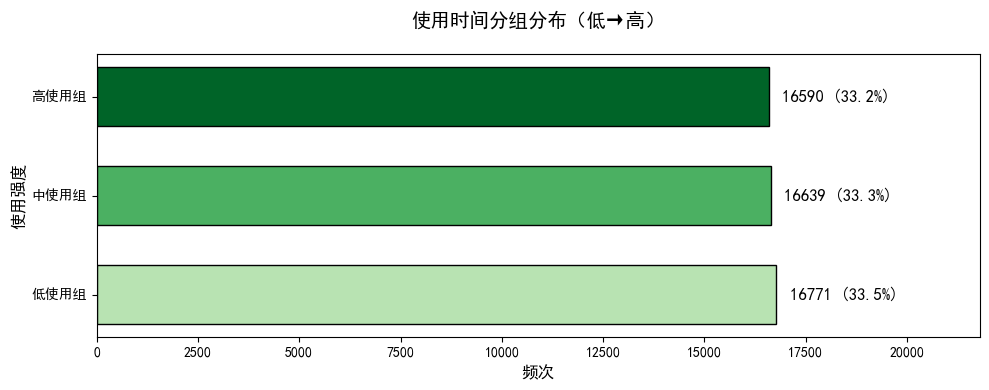

In [84]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# --- 步骤1：将使用时间分为三组 ---
# 使用分位数自动分组（33.3%, 66.6%为分割点）
df['usage_group'] = pd.qcut(df['app_usage_time_min'], 
                           q=[0, 0.333, 0.666, 1], 
                           labels=["低使用组", "中使用组", "高使用组"])

# --- 步骤2：准备数据 ---
usage_order = ["低使用组", "中使用组", "高使用组"]
usage_counts = df['usage_group'].value_counts().reindex(usage_order, fill_value=0)
total = len(df)
percentages = (usage_counts / total * 100).round(1)

# 生成渐变色（低→高：浅绿→深绿）
colors = plt.cm.Greens(np.linspace(0.3, 0.9, len(usage_order)))

# --- 步骤3：绘制图表 ---
fig, ax = plt.subplots(figsize=(10,4))

# 横向条形图
bars = ax.barh(
    usage_order, 
    usage_counts,
    color=colors,
    edgecolor='black',
    height=0.6
)

# 添加数据标签
for i, (count, percent) in enumerate(zip(usage_counts, percentages)):
    ax.text(
        count + max(usage_counts)*0.02,  # 动态偏移
        i,
        f'{count} ({percent}%)',
        va='center',
        fontsize=12
    )

# --- 图表样式设置 ---
ax.set_title("使用时间分组分布（低→高）", fontsize=14, pad=20)
ax.set_xlabel("频次", fontsize=12)
ax.set_ylabel("使用强度", fontsize=12)
ax.set_xlim(0, max(usage_counts)*1.3)  # 扩展x轴范围

plt.tight_layout()
plt.show()

In [34]:
df['match_outcome'].unique()  

array(['Mutual Match', 'Chat Ignored', 'Date Happened', 'No Action',
       'One-sided Like', 'Blocked', 'Relationship Formed', 'Catfished',
       'Ghosted', 'Instant Match'], dtype=object)

In [87]:
# 定义合并规则
def merge_match_result(outcome):
    if outcome in ['Relationship Formed', 'Date Happened']:
        return '成功建立关系'
    elif outcome in ['Mutual Match', 'Instant Match', 'Chat Ignored', 'No Action', 'Ghosted']:
        return '成功但无后续'
    elif outcome in ['One-sided Like', 'Blocked', 'Catfished']:
        return '失败'
    else:
        return '其他'  # 兜底处理未知类型

# 应用合并
df['match_result'] = df['match_outcome'].apply(merge_match_result)

# 验证分布
print(df['match_result'].value_counts())

match_result
成功但无后续    25032
失败        15186
成功建立关系     9782
Name: count, dtype: int64


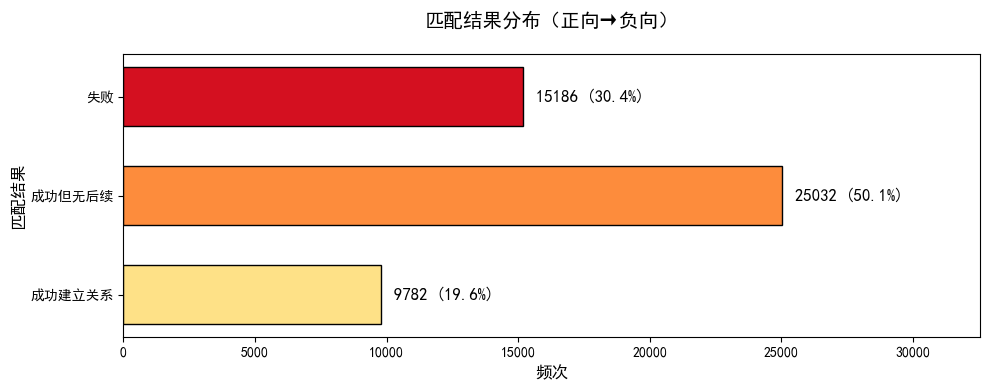

In [88]:


# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# --- 步骤1：定义匹配结果的显示顺序（从正向到负向）---
result_order = ['成功建立关系', '成功但无后续', '失败']

# --- 步骤2：准备数据 ---
result_counts = df['match_result'].value_counts().reindex(result_order, fill_value=0)
total = len(df)
percentages = (result_counts / total * 100).round(1)

# 生成渐变色（绿→黄→红，反映结果质量）
colors = plt.cm.YlOrRd(np.linspace(0.2, 0.8, len(result_order)))  # 从浅黄到深红

# --- 步骤3：绘制图表 ---
fig, ax = plt.subplots(figsize=(10, 4))

# 横向条形图
bars = ax.barh(
    result_order, 
    result_counts,
    color=colors,
    edgecolor='black',
    height=0.6
)

# 添加数据标签
for i, (count, percent) in enumerate(zip(result_counts, percentages)):
    ax.text(
        count + max(result_counts)*0.02,  # 动态偏移
        i,
        f'{count} ({percent}%)',
        va='center',
        fontsize=12,
        color='black'  # 确保黑色文字在浅色背景上可见
    )

# --- 图表样式设置 ---
ax.set_title("匹配结果分布（正向→负向）", fontsize=14, pad=20)
ax.set_xlabel("频次", fontsize=12)
ax.set_ylabel("匹配结果", fontsize=12)
ax.set_xlim(0, max(result_counts)*1.3)  # 扩展x轴范围

plt.tight_layout()
plt.show()

In [36]:
# shape返回 (行数, 列数)
total_rows = df.shape[0]
print(f"总数据量: {total_rows} 条")

总数据量: 50000 条
